# TP 0 — Séance d'introduction
### Algorithmique avancée et complexité — Master IA

| | |
|---|---|
| **Cours & TD** | Dr. Benyamina Ahmed |
| **TP** | Mahkouka Mohamed Fouad |
| **Durée** | 1 séance |

---

## 🎯 Objectifs de la séance

À la fin de cette séance, vous saurez :

1. **Installer Python** et vérifier qu'il fonctionne.
2. **Installer VS Code** et y utiliser des **notebooks Jupyter**.
3. **Utiliser Git et GitHub** pour sauvegarder et rendre vos TP.
4. **Rappeler les bases de Python** utiles pour le module.
5. **Mesurer un algorithme** : compter des opérations, chronométrer, tracer une courbe en échelle log, ce qui vous servira dès le **TP 1**.

## 🗺️ Plan

| Partie | Contenu | Durée indicative |
|---|---|---|
| 1 | Installation de Python | 15 min |
| 2 | VS Code + Jupyter | 15 min |
| 3 | Git & GitHub | 25 min |
| 4 | Rappels de Python | 40 min |
| 5 | Mesurer un algorithme (préparation TP 1) | 20 min |
| 6 | Exercices + rendu sur GitHub | reste |

> 💡 **Lien avec le module** : tout le module porte sur la façon dont le **temps** et la **mémoire** d'un algorithme évoluent quand la taille des données $n$ augmente. Pour l'observer, il faut un environnement qui marche. C'est l'objet de cette séance.

---
# Partie 1 — Installer Python

## 1.1 Windows

1. Aller sur **https://www.python.org/downloads/** et télécharger la dernière version **3.12 ou plus**.
2. Lancer l'installateur.
3. ⚠️ **Cocher la case « Add python.exe to PATH »** en bas de la première fenêtre. C'est l'oubli le plus fréquent.
4. Cliquer sur **Install Now**.
5. Ouvrir un terminal (**PowerShell**) et vérifier :

```powershell
python --version
pip --version
```

> Si `python` ouvre le Microsoft Store, désactivez les alias dans *Paramètres → Applications → Paramètres d'application avancés → Alias d'exécution d'application*, ou utilisez `py --version`.

## 1.2 macOS

Option A : installateur officiel depuis **python.org** (le plus simple).
Option B : avec [Homebrew](https://brew.sh) :

```bash
brew install python
python3 --version
```

> Sur macOS et Linux, la commande s'appelle souvent `python3` et `pip3`.

## 1.3 Linux (Ubuntu/Debian)

```bash
sudo apt update
sudo apt install python3 python3-pip python3-venv
python3 --version
```

## 1.4 Créer un environnement virtuel (recommandé)

Un **environnement virtuel** isole les bibliothèques d'un projet : ce que vous installez pour ce module ne casse pas un autre projet.

```bash
# dans le dossier de votre projet
python -m venv .venv

# activer l'environnement
# Windows :
.venv\Scripts\activate
# macOS / Linux :
source .venv/bin/activate

# installer ce dont on a besoin pour le module
pip install jupyter ipykernel matplotlib numpy
```

Quand l'environnement est actif, le terminal affiche `(.venv)` au début de la ligne.

---
# Partie 2 — VS Code + Jupyter

## 2.1 Installation

1. Télécharger **Visual Studio Code** : https://code.visualstudio.com
2. Ouvrir VS Code → onglet **Extensions** (`Ctrl+Shift+X`, ou `Cmd+Shift+X` sur Mac).
3. Installer :
   - **Python** (Microsoft)
   - **Jupyter** (Microsoft)

## 2.2 Ouvrir un notebook

1. **Fichier → Ouvrir le dossier…** et choisir votre dossier de TP.
2. Créer un fichier `test.ipynb` (ou `Ctrl+Shift+P` → *Create: New Jupyter Notebook*).
3. En haut à droite, cliquer sur **Select Kernel** → **Python Environments** → choisir **`.venv`**.
4. Écrire `print("Bonjour")` dans une cellule et appuyer sur `Shift+Entrée`.

## 2.3 Les cellules

Un notebook contient deux types de cellules :

- **Code** : du Python qu'on exécute.
- **Markdown** : du texte mis en forme (titres, listes, formules $\LaTeX$ comme $O(n^2)$).

## 2.4 Raccourcis essentiels

| Action | Raccourci |
|---|---|
| Exécuter la cellule et passer à la suivante | `Shift + Entrée` |
| Exécuter la cellule sans bouger | `Ctrl + Entrée` |
| Mode commande (cellule bleue) | `Échap` |
| Insérer une cellule **au-dessus / en dessous** | `A` / `B` (mode commande) |
| Passer en **Markdown / Code** | `M` / `Y` (mode commande) |
| Supprimer la cellule | `D` `D` (mode commande) |
| Redémarrer le noyau | bouton **Restart** en haut |

> ⚠️ **Piège classique** : les cellules partagent la même mémoire **dans l'ordre où vous les exécutez**, pas dans l'ordre où elles apparaissent. En cas de comportement étrange : **Restart** puis **Run All**.

## 2.5 Vérifier votre environnement

Exécutez la cellule ci-dessous. Elle doit afficher votre version de Python et confirmer que les bibliothèques sont installées.

In [23]:
import sys, platform

print("Python      :", sys.version.split()[0])
print("Système     :", platform.system(), platform.release())
print("Exécutable  :", sys.executable)   # doit pointer vers votre .venv

for lib in ["matplotlib", "numpy"]:
    try:
        module = __import__(lib)
        print(f"✅ {lib:<11}: {module.__version__}")
    except ImportError:
        print(f"❌ {lib:<11}: absent → exécutez  pip install {lib}")

Python      : 3.13.8
Système     : Darwin 25.1.0
Exécutable  : /Users/macbook/.pyenv/versions/3.13.8/bin/python
✅ matplotlib : 3.10.7
✅ numpy      : 2.3.4


On peut aussi lancer une commande du terminal depuis une cellule en la préfixant par `!` :

In [24]:
!python --version
!git --version

Python 3.13.8
git version 2.50.1 (Apple Git-155)


---
# Partie 3 — Git & GitHub

## 3.1 Pourquoi ?

- **Git** est un logiciel qui garde **l'historique** de vos fichiers. On peut revenir en arrière et voir ce qui a changé.
- **GitHub** est un site qui héberge vos dépôts Git **en ligne** : sauvegarde, partage, travail en équipe.
- Dans ce module, **chaque TP sera rendu via GitHub**.

| Notion | Signification |
|---|---|
| **dépôt** (*repository*) | un dossier suivi par Git |
| **commit** | une « photo » de vos fichiers à un instant donné, avec un message |
| **push** | envoyer vos commits vers GitHub |
| **pull** | récupérer les commits depuis GitHub |
| **clone** | télécharger un dépôt GitHub sur votre machine |

## 3.2 Installation et configuration (une seule fois)

1. Créer un compte sur **https://github.com** (adresse universitaire conseillée : elle donne accès à [GitHub Education](https://education.github.com)).
2. Installer Git :
   - **Windows** : https://git-scm.com/download/win (garder les options par défaut)
   - **macOS** : `xcode-select --install` ou `brew install git`
   - **Linux** : `sudo apt install git`
3. Se présenter à Git :

```bash
git config --global user.name "Prénom Nom"
git config --global user.email "votre.email@univ.dz"
```

## 3.3 Créer votre dépôt de TP

1. Sur GitHub : **New repository** → nom : `aac-tp` → cocher **Add a README** → `.gitignore` : **Python** → **Create**.
2. Cloner le dépôt sur votre machine :

```bash
git clone https://github.com/<votre-pseudo>/aac-tp.git
cd aac-tp
```

> Dans VS Code : `Ctrl+Shift+P` → **Git: Clone** fait la même chose, avec connexion GitHub intégrée.

Organisation conseillée :

```
aac-tp/
├── README.md
├── .gitignore
├── tp0_introduction/
│   └── TP0_Introduction.ipynb
├── tp1_complexite/
│   └── ...
```

## 3.4 Le cycle de travail quotidien

```bash
git status                          # qu'est-ce qui a changé ?
git add tp0_introduction/           # préparer les fichiers
git commit -m "TP0 : exercices 1 à 4"  # enregistrer une version
git push                            # envoyer sur GitHub
```

```
 modifier ──► git add ──► git commit ──► git push ──► GitHub
    ▲                                                   │
    └──────────────────── git pull ◄────────────────────┘
```

> Dans VS Code, l'onglet **Source Control** (`Ctrl+Shift+G`) fait tout cela avec des boutons : **+** pour `add`, ✔ pour `commit`, **Sync** pour `push/pull`.

## 3.5 Bonnes pratiques

- Des **petits commits fréquents** avec un message clair (`"TP1 : ajout du programme 3"` plutôt que `"modif"`).
- Ne **jamais** committer le dossier `.venv/` : le `.gitignore` Python l'exclut déjà.
- Avant de rendre : **Restart & Run All**, pour que le notebook s'exécute de haut en bas sans erreur.

---
# Partie 4 — Rappels de Python

## 4.1 Variables et types

In [25]:
n = 10                 # int
pi = 3.14159           # float
nom = "Algorithme"     # str
trouve = False         # bool
rien = None            # NoneType

for v in [n, pi, nom, trouve, rien]:
    print(repr(v), "->", type(v).__name__)

10 -> int
3.14159 -> float
'Algorithme' -> str
False -> bool
None -> NoneType


Opérations utiles en algorithmique : attention à la différence entre `/` et `//`.

In [26]:
print(7 / 2)    # division réelle      -> 3.5
print(7 // 2)   # division entière     -> 3   (programme 4 du TP 1 !)
print(7 % 2)    # reste (modulo)       -> 1
print(2 ** 10)  # puissance            -> 1024

nom, n = "tri", 1000
print(f"L'algorithme {nom} sur n = {n:,} éléments")   # f-string

3.5
3
1
1024
L'algorithme tri sur n = 1,000 éléments


## 4.2 Structures de données de base

| Type | Exemple | Ordonné | Modifiable | Accès typique |
|---|---|---|---|---|
| `list` | `[3, 1, 2]` | oui | oui | par indice `T[i]` |
| `tuple` | `(3, 1, 2)` | oui | non | par indice |
| `dict` | `{"a": 1}` | (ordre d'insertion) | oui | par clé `d["a"]` |
| `set` | `{1, 2, 3}` | non | oui | test `x in s` |

> 🔎 Nous verrons au **chapitre 3** que `x in liste` et `x in ensemble` n'ont **pas du tout** le même coût.

In [27]:
T = [5, 3, 8, 1]
T.append(7)              # ajoute à la fin
print(T, len(T), T[0], T[-1])
print(T[1:3])            # tranche (slicing) : indices 1 et 2
print(sorted(T))         # nouvelle liste triée

notes = {"Ali": 15, "Sara": 17}
notes["Yacine"] = 12
for etudiant, note in notes.items():
    print(etudiant, "→", note)

vus = {1, 2, 3}
print(2 in vus, 9 in vus)

[5, 3, 8, 1, 7] 5 5 7
[3, 8]
[1, 3, 5, 7, 8]
Ali → 15
Sara → 17
Yacine → 12
True False


## 4.3 Conditions et boucles

In [28]:
x = 42
if x % 2 == 0:
    print(x, "est pair")
elif x < 0:
    print(x, "est négatif")
else:
    print(x, "est impair")

# for : nombre de répétitions connu
for i in range(5):        # 0, 1, 2, 3, 4
    print(i, end=" ")
print()

# while : on répète tant qu'une condition est vraie
n = 100
etapes = 0
while n > 1:
    n = n // 2
    etapes += 1
print("étapes pour ramener 100 à 1 :", etapes)

42 est pair
0 1 2 3 4 
étapes pour ramener 100 à 1 : 6


## 4.4 Fonctions

In [29]:
def maximum(T):
    # Renvoie le plus grand élément d'une liste non vide.
    m = T[0]
    for e in T[1:]:
        if e > m:
            m = e
    return m

print(maximum([4, 9, 2, 7]))

9


## 4.5 Compréhensions de liste

Une façon courte de construire une liste :

In [30]:
carres = [i * i for i in range(10)]
pairs  = [i for i in range(20) if i % 2 == 0]
print(carres)
print(pairs)

[0, 1, 4, 9, 16, 25, 36, 49, 64, 81]
[0, 2, 4, 6, 8, 10, 12, 14, 16, 18]


## 4.6 Récursivité

Une fonction **récursive** s'appelle elle-même. Il lui faut toujours un **cas de base**, sinon elle ne s'arrête jamais.

In [31]:
def factorielle(n):
    if n <= 1:          # cas de base
        return 1
    return n * factorielle(n - 1)

print([factorielle(k) for k in range(8)])

[1, 1, 2, 6, 24, 120, 720, 5040]


## 4.7 Modules utiles pour le module AAC

| Module | Usage |
|---|---|
| `time` | mesurer un temps d'exécution (`time.perf_counter()`) |
| `random` | générer des données de test |
| `math` | `log2`, `sqrt`, `floor`… |
| `matplotlib` | tracer des courbes |

In [32]:
import math, random

random.seed(0)                                    # résultats reproductibles
T = [random.randint(1, 100) for _ in range(10)]
print(T)
print(math.log2(1024), math.floor(math.log2(1000)))

[50, 98, 54, 6, 34, 66, 63, 52, 39, 62]
10.0 9


---
# Partie 5 — Mesurer un algorithme (préparation du TP 1)

Au **TP 1**, pour chaque programme, vous devrez :

1. **compter** le nombre d'exécutions de l'opération élémentaire ;
2. **mesurer** le temps d'exécution ;
3. **tracer** ces deux grandeurs en fonction de $n$, en **échelle logarithmique**.

On s'entraîne ici sur un exemple simple : **la somme des éléments d'une liste**.

## 5.1 Compter les opérations

In [33]:
def somme(T):
    compteur = 0
    s = 0
    for e in T:
        s += e
        compteur += 1          # opération élémentaire : une addition
    return s, compteur

print(somme([1, 2, 3, 4, 5]))

(15, 5)


## 5.2 Chronométrer

On utilise `time.perf_counter()`, l'horloge la plus précise disponible.
Une seule mesure est **bruitée** (autres programmes, cache…) : on répète **au moins 3 fois** et on garde la **moyenne**.

In [34]:
import time

def chrono(f, *args, repetitions=3):
    # Temps moyen (en secondes) de f(*args) sur plusieurs répétitions.
    total = 0.0
    for _ in range(repetitions):
        debut = time.perf_counter()
        f(*args)
        total += time.perf_counter() - debut
    return total / repetitions

print(f"{chrono(somme, list(range(100_000))):.6f} s")

0.004447 s


## 5.3 Remplir le tableau de résultats

In [35]:
tailles, operations, temps = [], [], []

print(f"{'n':>10} | {'opérations':>12} | {'temps (s)':>10}")
print("-" * 38)
for n in [10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    T = list(range(n))
    _, ops = somme(T)
    t = chrono(somme, T)
    tailles.append(n); operations.append(ops); temps.append(t)
    print(f"{n:>10,} | {ops:>12,} | {t:>10.6f}")

         n |   opérations |  temps (s)
--------------------------------------
        10 |           10 |   0.000001
       100 |          100 |   0.000003
     1,000 |        1,000 |   0.000042
    10,000 |       10,000 |   0.000614
   100,000 |      100,000 |   0.004696
 1,000,000 |    1,000,000 |   0.047628


## 5.4 Tracer en échelle log-log

Pourquoi le **log** ? $n$ va de $10$ à $10^6$ : sur une échelle normale, tous les petits points s'écrasent contre l'axe.
En échelle **log-log**, une croissance proportionnelle à $n^k$ devient une **droite de pente $k$**.

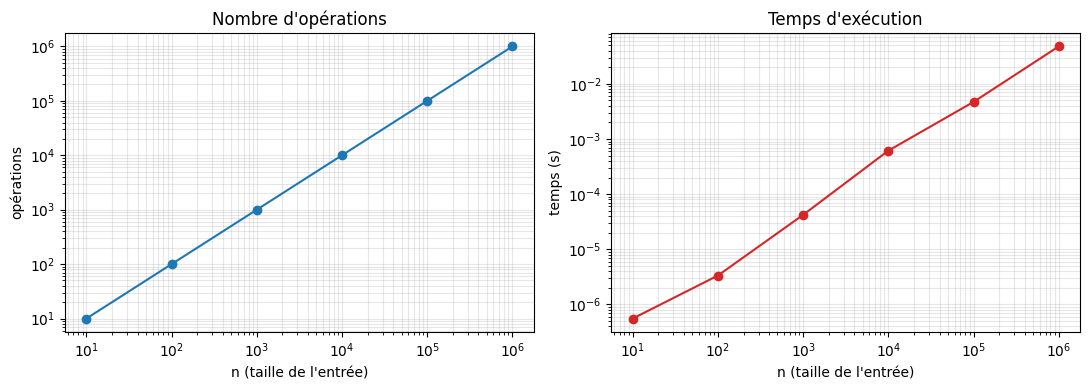

In [36]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.loglog(tailles, operations, "o-")
ax1.set(title="Nombre d'opérations", xlabel="n (taille de l'entrée)", ylabel="opérations")
ax1.grid(True, which="both", alpha=0.3)

ax2.loglog(tailles, temps, "o-", color="tab:red")
ax2.set(title="Temps d'exécution", xlabel="n (taille de l'entrée)", ylabel="temps (s)")
ax2.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

> 🧠 **Question** : que remarquez-vous sur la forme des deux courbes ? Que se passe-t-il pour le nombre d'opérations quand $n$ est multiplié par 10 ?
>
> *Votre réponse :* …

---
# Partie 6 — Exercices

Complétez chaque fonction, puis exécutez la cellule de vérification qui suit.
La fonction `verifier` affiche ✅ ou ❌ sans interrompre le notebook.

In [37]:
def verifier(nom, obtenu, attendu):
    print(("✅" if obtenu == attendu else "❌"), nom, "| obtenu :", obtenu, "| attendu :", attendu)

### Exercice 1 — Moyenne
Écrire `moyenne(T)` qui renvoie la moyenne des éléments d'une liste non vide, **sans** utiliser `sum()`.

In [38]:
def moyenne(T):
    # À COMPLÉTER
    pass

verifier("moyenne([2, 4, 6])", moyenne([2, 4, 6]), 4)
verifier("moyenne([5])", moyenne([5]), 5)

❌ moyenne([2, 4, 6]) | obtenu : None | attendu : 4
❌ moyenne([5]) | obtenu : None | attendu : 5


### Exercice 2 — Compter les occurrences
Écrire `occurrences(T, x)` qui renvoie le nombre de fois où `x` apparaît dans `T`, **sans** utiliser `T.count()`.

In [39]:
def occurrences(T, x):
    # À COMPLÉTER
    pass

verifier("occurrences([1,2,1,3,1], 1)", occurrences([1, 2, 1, 3, 1], 1), 3)
verifier("occurrences([], 7)", occurrences([], 7), 0)

❌ occurrences([1,2,1,3,1], 1) | obtenu : None | attendu : 3
❌ occurrences([], 7) | obtenu : None | attendu : 0


### Exercice 3 — Inverser une liste
Écrire `inverser(T)` qui renvoie une **nouvelle** liste à l'envers, **sans** `reversed()` ni `T[::-1]`.

In [40]:
def inverser(T):
    # À COMPLÉTER
    pass

verifier("inverser([1, 2, 3])", inverser([1, 2, 3]), [3, 2, 1])
verifier("inverser([])", inverser([]), [])

❌ inverser([1, 2, 3]) | obtenu : None | attendu : [3, 2, 1]
❌ inverser([]) | obtenu : None | attendu : []


### Exercice 4 — Fréquences avec un dictionnaire
Écrire `frequences(mot)` qui renvoie un dictionnaire `{lettre: nombre d'apparitions}`.

In [41]:
def frequences(mot):
    # À COMPLÉTER
    pass

verifier("frequences('banane')", frequences("banane"), {"b": 1, "a": 2, "n": 2, "e": 1})

❌ frequences('banane') | obtenu : None | attendu : {'b': 1, 'a': 2, 'n': 2, 'e': 1}


### Exercice 5 — Puissance récursive
Écrire `puissance(a, n)` **récursive** qui calcule $a^n$ pour $n \ge 0$, sans `**` ni `pow()`.

In [42]:
def puissance(a, n):
    # À COMPLÉTER
    pass

verifier("puissance(2, 10)", puissance(2, 10), 1024)
verifier("puissance(5, 0)", puissance(5, 0), 1)

❌ puissance(2, 10) | obtenu : None | attendu : 1024
❌ puissance(5, 0) | obtenu : None | attendu : 1


### Exercice 6 — Mesurer et comparer ⭐
Voici deux fonctions qui testent si une liste contient un **doublon**.

1. Ajoutez un **compteur** de comparaisons à chacune (l'opération élémentaire est la comparaison `==` ou `in`).
2. Exécutez-les pour `n = 10, 100, 1000, 2000` sur une liste **sans doublon** (`list(range(n))`).
3. Tracez le **nombre de comparaisons** des deux fonctions sur un même graphique **log-log**.
4. Décrivez **avec vos mots** (sans notation $O(\cdot)$) ce que vous observez quand $n$ est multiplié par 10.

In [43]:
def doublon_v1(T):
    compteur = 0
    for i in range(len(T)):
        for j in range(i + 1, len(T)):
            # À COMPLÉTER : incrémenter le compteur
            if T[i] == T[j]:
                return True, compteur
    return False, compteur

def doublon_v2(T):
    compteur = 0
    vus = set()
    for e in T:
        # À COMPLÉTER : incrémenter le compteur
        if e in vus:
            return True, compteur
        vus.add(e)
    return False, compteur

In [44]:
# À COMPLÉTER : boucle sur les tailles, collecte des compteurs, graphique log-log

> *Vos observations :* …

---
# 📤 Travail à rendre

1. Placez ce notebook dans `aac-tp/tp0_introduction/`.
2. Complétez les exercices.
3. **Restart & Run All** : tout doit s'exécuter sans erreur.
4. Envoyez-le sur GitHub :

```bash
git add tp0_introduction/
git commit -m "TP0 : introduction terminée"
git push
```

5. Envoyez le **lien de votre dépôt** à l'enseignant du TP.

---
# 📚 Récapitulatif

| Outil | À retenir |
|---|---|
| **Python** | ≥ 3.12, cocher *Add to PATH*, un `.venv` par projet |
| **VS Code** | extensions *Python* + *Jupyter*, sélectionner le bon noyau |
| **Git** | `status` → `add` → `commit` → `push` |
| **Mesure** | compteur pour les opérations, `perf_counter` × 3 pour le temps, `loglog` pour tracer |

### Ressources
- Tutoriel Python officiel (FR) : https://docs.python.org/fr/3/tutorial/
- Jupyter dans VS Code : https://code.visualstudio.com/docs/datascience/jupyter-notebooks
- Git, guide interactif : https://learngitbranching.js.org/?locale=fr_FR
- GitHub Docs : https://docs.github.com/fr

### ➡️ Prochaine séance : **TP 1 — Découverte expérimentale de la complexité algorithmique**
Cinq programmes (parcours, recherche séquentielle, boucles imbriquées, divisions par 2, Fibonacci récursif) à mesurer avec exactement les outils de la Partie 5.